## MMM study

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import shap


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [6]:
df=pd.read_csv("mmm_dataset.csv")
df.drop(columns=['competitor_spend'],inplace=True)

In [7]:
df.head(1)

,date,holiday,sales_promotion,instagram_spend,google_ads_spend,tv_spend,youtube_spend,newspaper_spend,influencer_spend,ott_spend,sales
0,03-01-2022,0,BOGO,54880.0,NaN,47580.0,57190.0,NaN,34610.0,NaN,1084031.0


(array([21., 20., 18.,  6., 16., 19., 21., 11., 12.,  6.]),
 array([14240., 18134., 22028., 25922., 29816., 33710., 37604., 41498.,
        45392., 49286., 53180.]),
 <BarContainer object of 10 artists>)

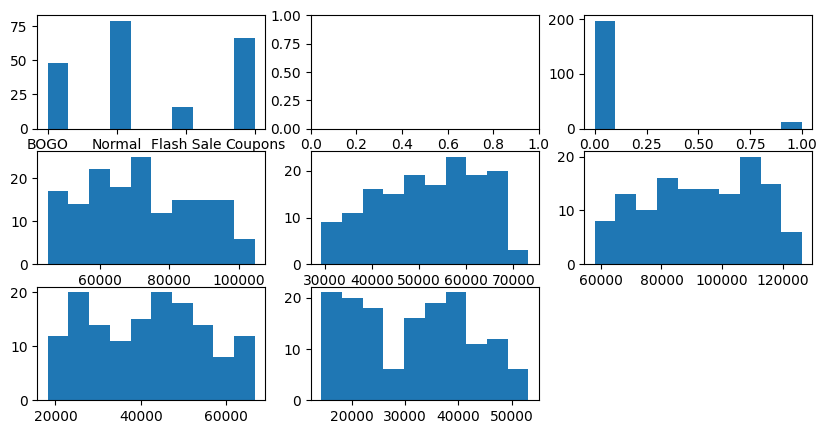

In [8]:
plt.figure(figsize=(10,5))
plt.subplot(3,3,1)
plt.hist(df['sales_promotion'])
plt.subplot(3,3,2)
plt.subplot(3,3,3)
plt.hist(df['holiday'])
plt.subplot(3,3,4)
plt.hist(df['instagram_spend'])
plt.subplot(3,3,5)
plt.hist(df['tv_spend'])
plt.subplot(3,3,6)
plt.hist(df['google_ads_spend'])
plt.subplot(3,3,7)
plt.hist(df['youtube_spend'])
plt.subplot(3,3,8)
plt.hist(df['influencer_spend'])

In [9]:
#replace NANs with zeros
df.fillna(0,inplace=True)

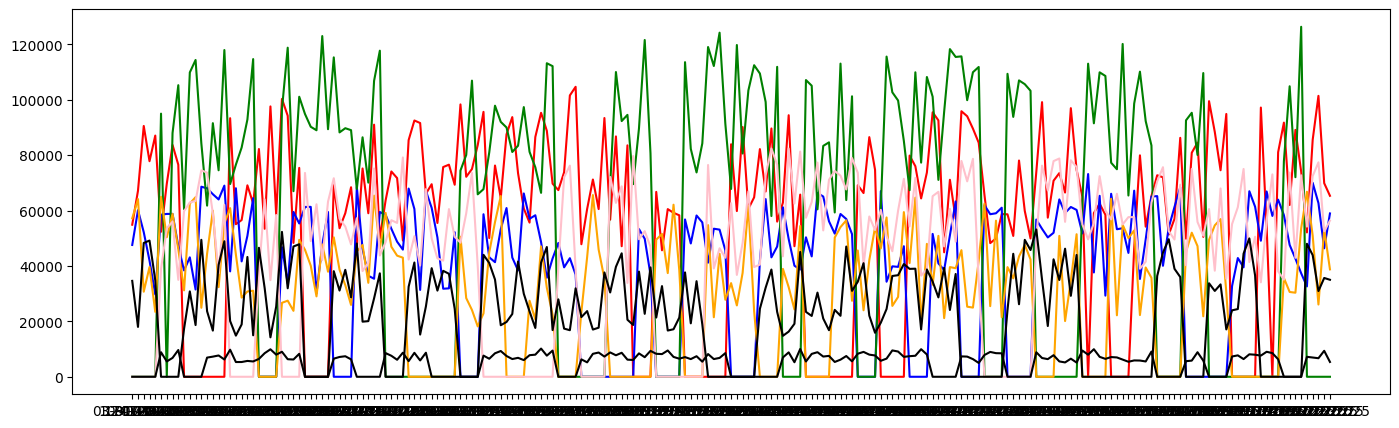

In [10]:
#plot time line of evolution of marketing spend throughout time
plt.figure(figsize=(17,5))
#different colors for each channel
plt.plot(df['date'],df['instagram_spend'], color='red' )
plt.plot(df['date'],df['tv_spend'], color='blue')
plt.plot(df['date'],df['google_ads_spend'], color='green')
plt.plot(df['date'],df['youtube_spend'], color='orange')
plt.plot(df['date'],df['ott_spend'],color='pink')
plt.plot(df['date'],df['influencer_spend'],color='black')
plt.plot(df['date'],df['newspaper_spend'],color='black')


In [11]:
# Create dummy varaibles for sales promotion
df = pd.get_dummies(df, columns=['sales_promotion'], drop_first=True, dtype=int)
df.rename(columns={'sales_promotion_Coupons': 'sales_promotion_coupon', 'sales_promotion_Normal': 'sales_promotion_normal', 'sales_promotion_Flash Sale': 'sales_promotion_flash'}, inplace=True)

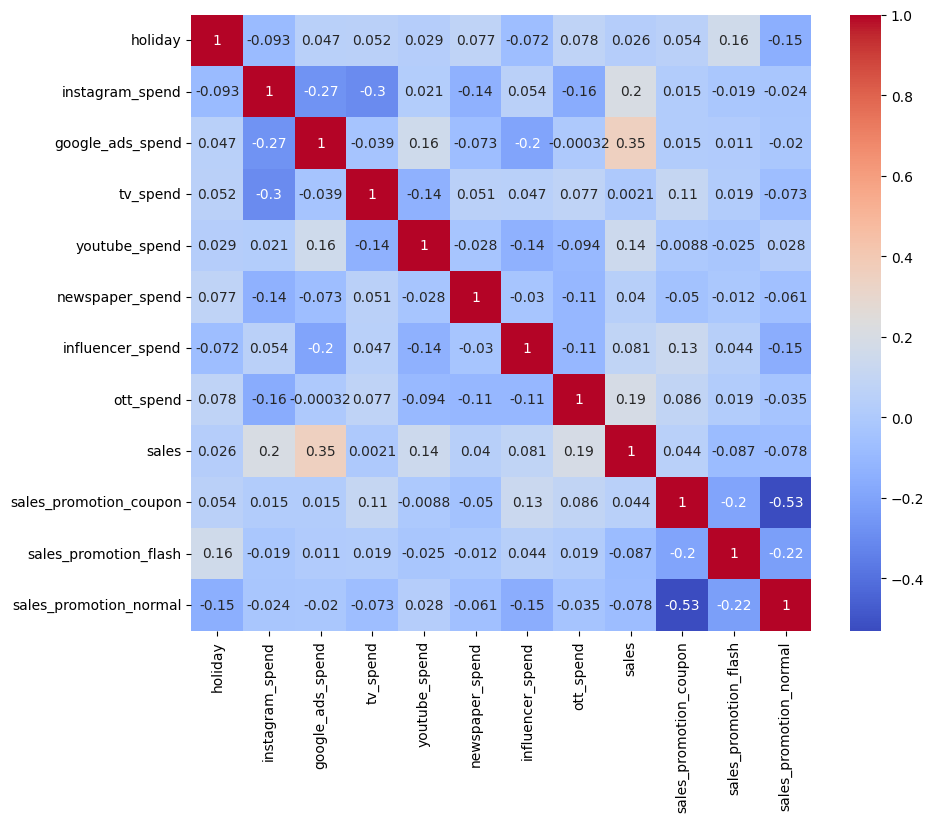

In [13]:
# Plot correlation matrix:
df_corr=df.drop(columns=['date'])
plt.figure(figsize=(10, 8))
sns.heatmap(df_corr.corr(), annot=True, cmap='coolwarm')
plt.show()

In [15]:
# Calculate spend share for each channel
channels = ['instagram_spend', 'tv_spend', 'google_ads_spend', 'youtube_spend', 'ott_spend', 'influencer_spend', 'newspaper_spend']
df_channels=df[channels]
total_spend_per_channel = df_channels.sum(axis=0)
spend_share = total_spend_per_channel / total_spend_per_channel.sum()

print("Spend share per channel:")
print(spend_share)

# Use spend share to inform prior on channel contributions
n_channels = len(channels)


Spend share per channel:
instagram_spend     0.218823
tv_spend            0.150542
google_ads_spend    0.230006
youtube_spend       0.114556
ott_spend           0.175594
influencer_spend    0.090018
newspaper_spend     0.020460
dtype: float64


## Split data set for training and testing
Training set: 80% of innitial values

Test set: 20% latests values


In [ ]:
df_train=df.iloc[:int(0.8*len(df))]
df_test=df.iloc[int(0.8*len(df)):]

print(df.shape)
print(df_train.shape)
print(df_test.shape)

(209, 13)
(167, 13)
(42, 13)


## Naive regression method

In [ ]:
regression_model=smf.ols('sales~instagram_spend+tv_spend+google_ads_spend+youtube_spend+ott_spend+influencer_spend+newspaper_spend+sales_promotion_coupon+sales_promotion_normal+sales_promotion_flash',data=df_train).fit()
print(regression_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.339
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     7.993
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           2.48e-10
Time:                        12:09:38   Log-Likelihood:                -2405.4
No. Observations:                 167   AIC:                             4833.
Df Residuals:                     156   BIC:                             4867.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept               1.00

MAE: 189266.3815684709
MSE: 56729211826.4464
RMSE: 238178.94916731495


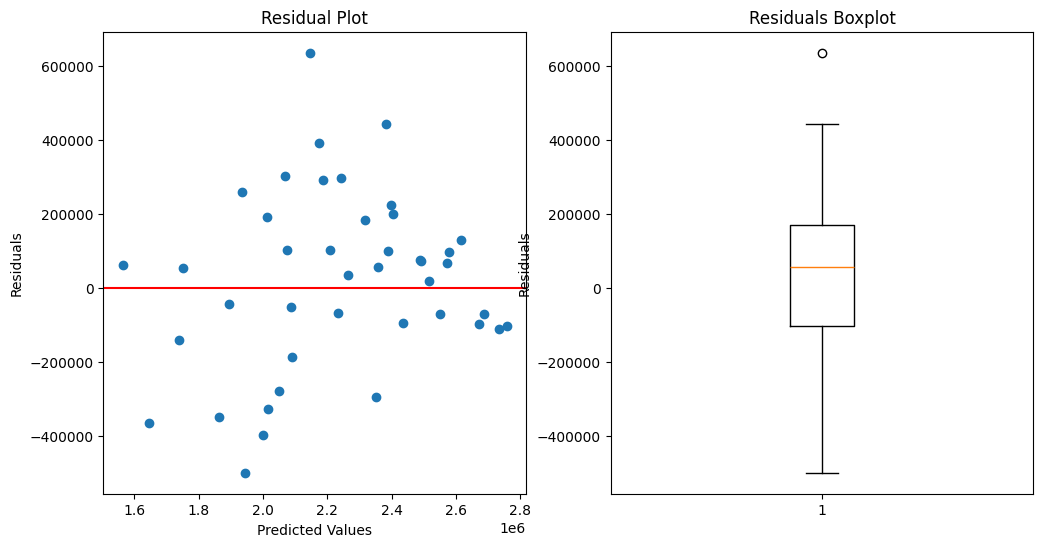

In [ ]:
## test model with out of sample data:
pred=regression_model.predict(df_test)
error=df_test['sales']-pred

# Regression error metrics
mae = mean_absolute_error(df_test['sales'], pred)
mse = mean_squared_error(df_test['sales'], pred)
rmse = np.sqrt(mse)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

#Plot residuals
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(pred, error)
plt.axhline(y=0, color='r', linestyle='-')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.subplot(1, 2, 2)
plt.boxplot(error)
plt.ylabel('Residuals')
plt.title('Residuals Boxplot')
plt.show()

## ML approach
This method uses an XGBoost Model to predict sales. Then, we get shapley values to evaluate their contribution

In [ ]:
X_train=df_train.drop(columns=['sales','date'])
y_train=df_train['sales']
X_test=df_test.drop(columns=['sales','date'])
y_test=df_test['sales']



In [ ]:
xg_boost_model = XGBRegressor(random_state=42)
xg_boost_model.fit(X_train, y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
predicted = xg_boost_model.predict(X_test)

errors = y_test - predicted

print("R²:", r2_score(y_test, predicted))
print("MAE:", mean_absolute_error(y_test, predicted))
print("MSE:", mean_squared_error(y_test, predicted))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predicted)))

R²: 0.16099174989077059
MAE: 295072.8095238095
MSE: 144509496401.74478
RMSE: 380144.04691083194


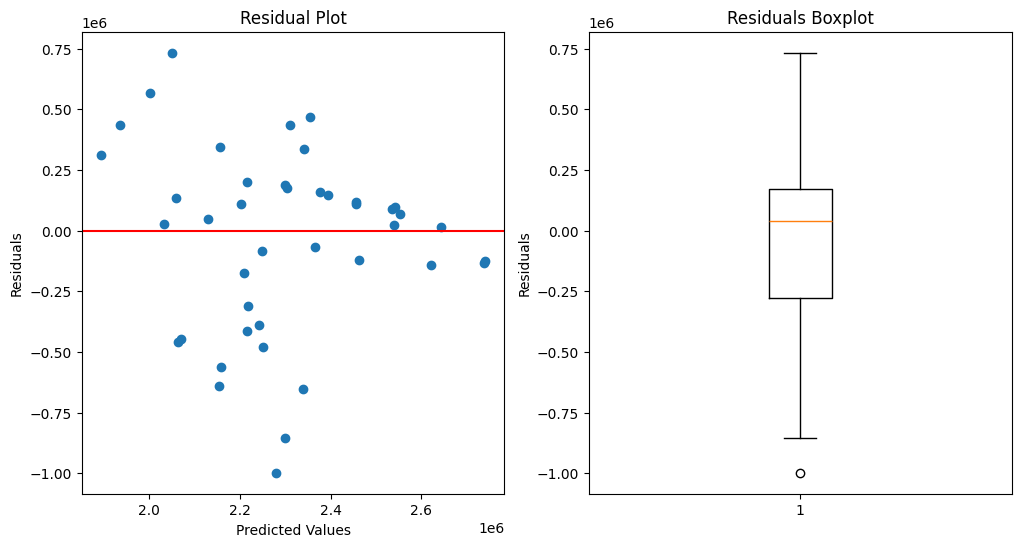

In [ ]:
#Plot residuals
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(predicted, errors)
plt.axhline(y=0, color='r', linestyle='-')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.subplot(1, 2, 2)
plt.boxplot(errors)
plt.ylabel('Residuals')
plt.title('Residuals Boxplot')
plt.show()

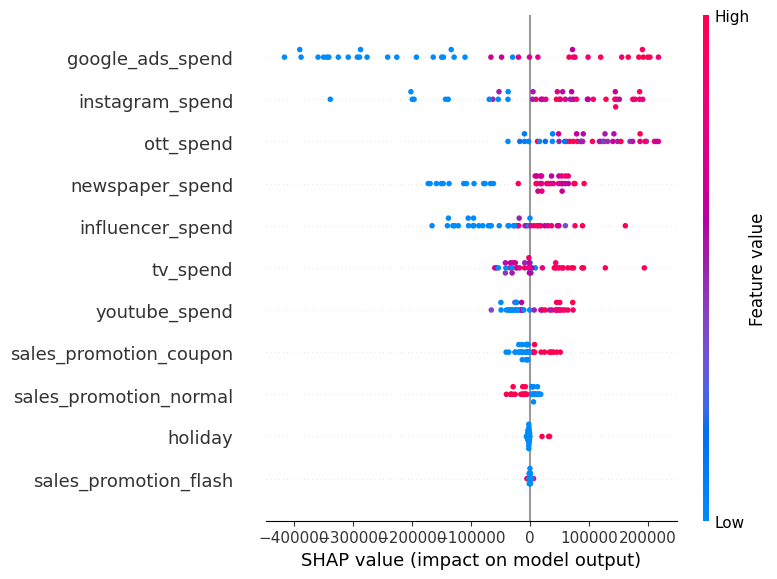

In [ ]:

# Explain XGBoost model
explainer = shap.TreeExplainer(xg_boost_model)
shap_values = explainer(X_test)

# Feature importance plot
shap.summary_plot(shap_values.values, X_test)

In [ ]:
#Bayesian & Causal MMM

In [ ]:

from pymc_marketing.mmm import (
    MMM,
    GeometricAdstock,
    LogisticSaturation
)

# Marketing channels
channels = [
    'google_ads_spend',
    'instagram_spend',
    'ott_spend',
    'newspaper_spend',
    'influencer_spend',
    'tv_spend',
    'youtube_spend'
]

# Control variables
controls = [
    'sales_promotion_coupon',
    'sales_promotion_normal',
    'sales_promotion_flash',
    'holiday'
]

# Prepare data
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y')
df = df.sort_values('date')

X = df[['date'] + channels + controls]
y = df['sales'].rename('y')

# Define Bayesian MMM
mmm = MMM(
    date_column='date',
    channel_columns=channels,
    control_columns=controls,
    adstock=GeometricAdstock(l_max=8),
    saturation=LogisticSaturation(),
    yearly_seasonality=2
)

# Fit model
mmm.fit(X, y)

Output()

/usr/local/lib/python3.13/dist-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.
  warnings.warn(


Output()

<xarray.DataTree>
Group: /
│   Attributes: (12/24)
│       id:                         eebddbf57febc146
│       model_type:                 MMMM (Multi-Dimensional Marketing Mix Model)
│       version:                    0.0.2
│       sampler_config:             {}
│       model_config:               {"intercept": {"dist": "Normal", "kwargs": {"...
│       __serialization_version__:  1
│       ...                         ...
│       scaling:                    {"__type__": "pymc_marketing.mmm.scaling.Scal...
│       dag:                        null
│       treatment_nodes:            null
│       outcome_node:               null
│       mu_effects:                 []
│       cost_per_unit:              null
├── Group: /posterior
│       Dimensions:                                  (chain: 2, draw: 1000, channel: 7,
│                                                     fourier_mode: 4, control: 4,
│                                                     date: 209)
│       Coordinates:
│         * chain                                    (chain) int64 16B 0 1
│         * draw                                     (draw) int64 8kB 0 1 2 ... 998 999
│         * channel                                  (channel) <U16 448B 'google_ads_...
│         * fourier_mode                             (fourier_mode) <U5 80B 'sin_1' ....
│         * control                                  (control) <U22 352B 'sales_promo...
│         * date                                     (date) datetime64[ns] 2kB 2022-0...
│       Data variables: (12/13)
│           adstock_alpha                            (chain, draw, channel) float64 112kB ...
│           saturation_lam                           (chain, draw, channel) float64 112kB ...
│           saturation_beta                          (chain, draw, channel) float64 112kB ...
│           gamma_fourier                            (chain, draw, fourier_mode) float64 64kB ...
│           gamma_control                            (chain, draw, control) float64 64kB ...
│           intercept_contribution                   (chain, draw) float64 16kB 0.045...
│           ...                                       ...
│           total_media_contribution_original_scale  (chain, draw) float64 16kB 4.558...
│           mu                                       (chain, draw, date) float64 3MB ...
│           yearly_seasonality_contribution          (chain, draw, date) float64 3MB ...
│           fourier_contribution                     (chain, draw, date, fourier_mode) float64 13MB ...
│           control_contribution                     (chain, draw, date, control) float64 13MB ...
│           channel_contribution                     (chain, draw, date, channel) float64 23MB ...
│       Attributes:
│           created_at:                 2026-10-17T12:14:16.804145+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
│           sampling_time:              73.93697357177734
│           tuning_steps:               1000
│           pymc_marketing_version:     1.2.0
├── Group: /sample_stats
│       Dimensions:                (chain: 2, draw: 1000)
│       Coordinates:
│         * chain                  (chain) int64 16B 0 1
│         * draw                   (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│       Data variables: (12/18)
│           lp                     (chain, draw) float64 16kB 162.9 162.4 ... 167.7
│           smallest_eigval        (chain, draw) float64 16kB nan nan nan ... nan nan
│           perf_counter_diff      (chain, draw) float64 16kB 0.03477 ... 0.01064
│           tree_depth             (chain, draw) int64 16kB 6 6 7 6 6 6 ... 6 6 6 6 6 6
│           diverging              (chain, draw) bool 2kB False False ... False False
│           energy_error   